In [1]:
from langgraph.graph import StateGraph, START, END
from typing import Annotated, TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [4]:
parent_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")
subgraph_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [5]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi. Keep it natural and clear. Do not add extra content.
Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {"answer_hin": translated_text}

In [6]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node("translate_text", translate_text)

subgraph_builder.add_edge(START, "translate_text")
subgraph_builder.add_edge("translate_text", END)

subgraph = subgraph_builder.compile()

In [7]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state["question"]}").content

    return {"answer_eng": answer}

In [8]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, "answer")
parent_builder.add_edge("answer", "translate")
parent_builder.add_edge('translate', END)

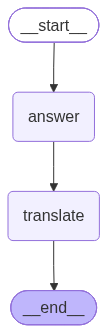

In [9]:
graph = parent_builder.compile()

graph

In [10]:
graph.invoke({"question": 'what is cloud computing'})

{'question': 'what is cloud computing',
 'answer_eng': [{'type': 'text',
   'text': '**Cloud computing** is the delivery of computing services over the internet—including data storage, servers, databases, networking, and software—using a pay-as-you-go pricing model. \n\nInstead of buying, owning, and maintaining your own physical data centers and servers, you rent access to them from a cloud provider (such as Amazon Web Services, Microsoft Azure, or Google Cloud).\n\nHere is a breakdown to help you understand it better:\n\n### 1. The Analogy: Electricity\nThink of cloud computing like the electrical grid. When you turn on a lamp, you don’t own the power plant or worry about how electricity is generated; you just plug it in and pay for the electricity you use. Cloud computing works the same way, but for digital resources (computing power and data).\n\n### 2. Key Characteristics\n* **On-demand self-service:** You can provision computing resources (like server time or network storage) whe